# Exploring the Lorenz parameter space (Strogatz §9.5)

**Author:** Julien Emile-Geay
**Date:** Nov 19 2026

_Description:_ Reproduces, with the `Lorenz63` critter, the five figures of Section 9.5 ("Exploring Parameter Space") of Strogatz, *Nonlinear Dynamics and Chaos* (2nd ed.). It also leverages the `cc.Forcing` construct to implement an analysis suggested in that chapter.

_Correspondence:_
The `Lorenz63` critter uses Lorenz's equations, with `sigma`, `rho` and `beta` playing the roles of Strogatz's $\sigma$, $r$ and $b$ (Section 9.2 of the book). We keep `sigma=10`, `beta=8/3` fixed throughout and vary explores the system's behavior as `rho` (the Rayleigh number) is varied.

| Book figure | Content | Section below |
|---|---|---|
| 9.5.1 | Bifurcation diagram for small $r$ | [Small r](#small-r) |
| 9.5.2–9.5.3 | Transient chaos at $r=21$ | [Transient chaos](#transient) |
| 9.5.4–9.5.5 | Limit cycle at $r=350$ | [Large r](#large-r) |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
import climatecritters as cc
from climatecritters.model_critters.lorenz import Lorenz63

sigma, b = 10.0, 8 / 3     # held fixed throughout Section 9.5

# Figure style, adapted from the borehole_val project: left/bottom spines only, light dotted
# grid, frameless legends, bold titles, and a small palette used consistently below.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Arial', 'mathtext.it': 'Arial:italic',
    'mathtext.bf': 'Arial:bold', 'mathtext.cal': 'Arial',
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'figure.titlesize': 14, 'figure.titleweight': 'bold',
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 1,
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '0.85', 'grid.linestyle': ':', 'grid.linewidth': 0.8,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.width': 1, 'ytick.major.width': 1,
    'legend.frameon': False,
    'figure.dpi': 110,
})
BLUE, RED, ORANGE, INK = '#2c7bb6', '#c0182b', '#f28e2b', '0.15'

<a id="small-r"></a>
## Small r: bifurcation diagram (Figure 9.5.1)

We compute the ingredients of Figure 9.5.1 numerically. First the fixed points: the origin and the symmetric pair $C^+$, $C^-$. Their expressions, and the value $r_H$ at which $C^\pm$ lose stability, are derived in Section 9.2 of the book. We classify stability from the eigenvalues of the Jacobian.

In [2]:
def jacobian(x, y, z, r):
    return np.array([[-sigma, sigma, 0.0],
                     [r - z, -1.0, -x],
                     [y, x, -b]])

def max_real_eig(point, r):
    return np.linalg.eigvals(jacobian(*point, r)).real.max()

r_H = sigma * (sigma + b + 3) / (sigma - b - 1)
r_grid = np.linspace(0, 28, 1401)

origin_stable = np.array([max_real_eig((0, 0, 0), r) < 0 for r in r_grid])
r_C = r_grid[r_grid > 1]
x_C = np.sqrt(b * (r_C - 1))
C_stable = np.array([max_real_eig((xc, xc, r - 1), r) < 0 for xc, r in zip(x_C, r_C)])

print(f"Analytic Hopf point            r_H = {r_H:.4f}")
print(f"Numerical loss of C+ stability r   = {r_C[~C_stable][0]:.2f}")
print(f"Numerical loss of 0 stability  r   = {r_grid[~origin_stable][0]:.2f}")

Analytic Hopf point            r_H = 24.7368
Numerical loss of C+ stability r   = 24.74
Numerical loss of 0 stability  r   = 1.00


Next, the unstable limit cycles (dashed in the book's figure). Forward integration can't find them, because they repel trajectories. Instead we find them by **shooting**: we solve for a starting point on the plane through $C^+$ and a period $T$ such that the trajectory returns to its starting point after time $T$. Then we follow the solution in $r$ by **continuation**, using each converged cycle to seed the next.

The flow map is the `Lorenz63` critter itself, integrated with SciPy's `DOP853` at tight tolerances (`integrate` forwards `method` and `kwargs` to `solve_ivp`). The continuation takes about 15 s. The `shoot` and `continue_cycle` functions are prototypes of the utility proposed in [#52](https://github.com/LinkedEarth/ClimateCritters/issues/52).

In [3]:
def flow(p, T, r, output_time=None):
    """Flow map: integrate the Lorenz63 critter from p over a time T. Returns a cc Output."""
    model = Lorenz63(sigma=sigma, rho=r, beta=b)
    return model.integrate(t_span=(0, T), y0=p, method='DOP853', output_time=output_time,
                           kwargs={'rtol': 1e-12, 'atol': 1e-12})

def shoot(r, guess):
    """Newton solve for (x0, y0, T) of a periodic orbit through the plane z = r-1."""
    def residual(q):
        p0 = [q[0], q[1], r - 1]
        return flow(p0, q[2], r).solution.y[-1] - p0      # final state minus initial state
    q, info, ier, _ = fsolve(residual, guess, full_output=True, xtol=1e-12)
    return q, np.linalg.norm(info['fvec'])

def continue_cycle(r_values, q_start):
    """Natural-parameter continuation with a secant predictor."""
    rows, qs, rs = [], [], []
    for r in r_values:
        if len(qs) < 2:
            guess = qs[-1] if qs else q_start
        else:
            guess = qs[-1] + (qs[-1] - qs[-2]) * (r - rs[-1]) / (rs[-1] - rs[-2])
        q, res = shoot(r, guess)
        if res > 1e-8 or q[2] < 0.1:          # lost the branch
            break
        # one period of the converged cycle, sampled on 1000 points
        out = flow([q[0], q[1], r - 1], q[2], r, output_time=np.linspace(0, q[2], 1000))
        orbit = np.vstack([out.state_variables[v] for v in 'xyz'])
        rows.append(dict(r=r, q=q, T=q[2], xmin=orbit[0].min(), xmax=orbit[0].max(), orbit=orbit))
        qs.append(q); rs.append(r)
    return rows

# Starting guess at r = 20, obtained by bisecting for the boundary between initial
# conditions that spiral into C+ and those that escape to the other lobe
q20 = np.array([10.988, 14.279, 0.877])

up   = continue_cycle(np.arange(20.0, 24.73, 0.05), q20)       # toward the Hopf point
down = continue_cycle(np.arange(20.0, 14.15, -0.05), q20)      # toward the homoclinic orbit
cycles = sorted(down[1:] + up, key=lambda d: d['r'])
print(f"Cycle branch computed for {cycles[0]['r']:.2f} <= r <= {cycles[-1]['r']:.2f} "
      f"({len(cycles)} values of r)")
print(f"Period: T = {cycles[-1]['T']:.3f} near r_H,  T = {cycles[0]['T']:.3f} at r = {cycles[0]['r']:.2f}")

Cycle branch computed for 14.20 <= r <= 24.70 (211 values of r)
Period: T = 0.654 near r_H,  T = 2.073 at r = 14.20


Below $r\approx14.2$ the continuation stops converging. As the cycle approaches the homoclinic orbit its period diverges. Even so, its minimum $x$ visibly heads toward 0.

**Solver check.** As an independent check, we integrate one period of a few cycles with a different scheme (`RK45`) and measure how far each trajectory lands from its start.

In [4]:
for d in cycles[::len(cycles) // 4]:
    r, (x0, y0, T) = d['r'], d['q']
    out = Lorenz63(sigma=sigma, rho=r, beta=b).integrate(
        t_span=(0, T), y0=[x0, y0, r - 1], method='RK45', kwargs={'rtol': 1e-12, 'atol': 1e-12})
    end = out.solution.y[-1]
    print(f"r = {r:6.2f}   T = {T:.4f}   |phi_T(p) - p| = {np.linalg.norm(end - [x0, y0, r - 1]):.1e}")

r =  14.20   T = 2.0729   |phi_T(p) - p| = 1.2e-07
r =  16.80   T = 1.1743   |phi_T(p) - p| = 5.5e-10
r =  19.40   T = 0.9179   |phi_T(p) - p| = 1.4e-10
r =  22.00   T = 0.7644   |phi_T(p) - p| = 4.5e-11
r =  24.60   T = 0.6576   |phi_T(p) - p| = 2.7e-11


Now we assemble Figure 9.5.1. As in the book, only the $C^+$ branch is drawn; the $C^-$ branch is its mirror image. The onset of the strange attractor ($r\approx24.06$) can't be found by local analysis, so we take its value from the book. The right panel shows the cycles in the $(x,z)$ plane.

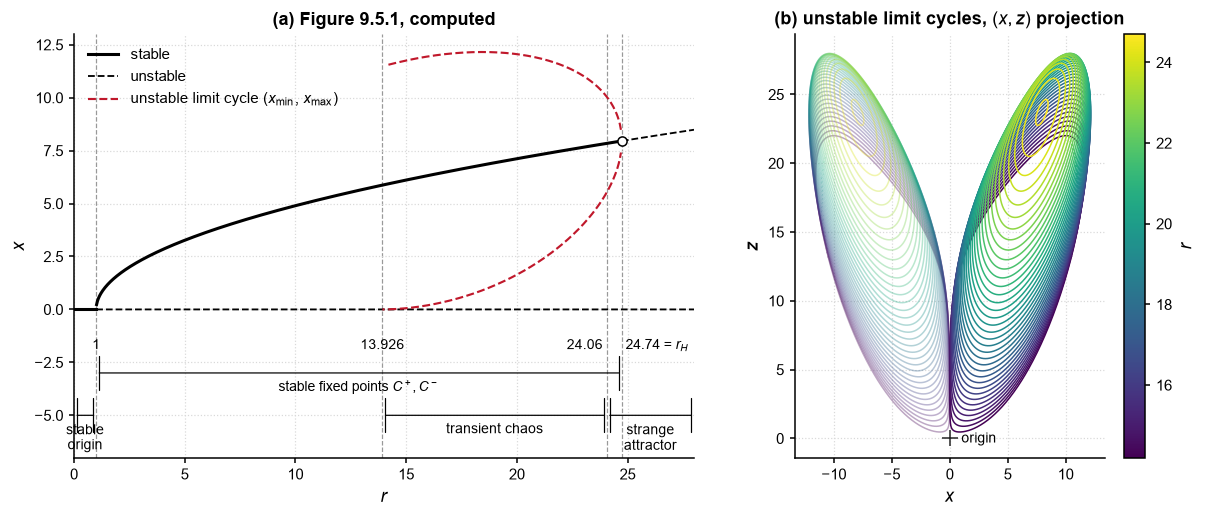

In [10]:
r_homoclinic, r_strange = 13.926, 24.06
r_cyc = np.array([d['r'] for d in cycles])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.6, 1]})

# --- (a) bifurcation diagram ---
ax.plot(r_grid[origin_stable], 0 * r_grid[origin_stable], 'k-', lw=2)
ax.plot(r_grid[~origin_stable], 0 * r_grid[~origin_stable], 'k--', lw=1.2)
ax.plot(r_C[C_stable], x_C[C_stable], 'k-', lw=2, label='stable')
ax.plot(r_C[~C_stable], x_C[~C_stable], 'k--', lw=1.2, label='unstable')
ax.plot(r_cyc, [d['xmax'] for d in cycles], '--', color=RED, lw=1.4,
        label='unstable limit cycle ($x_{\\min}$, $x_{\\max}$)')
ax.plot(r_cyc, [d['xmin'] for d in cycles], '--', color=RED, lw=1.4)
# x_min of the cycle reaches 0 at the homoclinic point (dotted: not computed)
ax.plot([r_homoclinic, r_cyc[0]], [0, cycles[0]['xmin']], ':', color=RED, lw=1.4)
ax.plot(r_H, np.sqrt(b * (r_H - 1)), 'o', mfc='white', mec='k', zorder=5)

for rv, lab, ha in [(1, '1', 'center'), (r_homoclinic, '13.926', 'center'),
                   (r_strange, '24.06 ', 'right'), (r_H, f' {r_H:.2f} = $r_H$', 'left')]:
    ax.axvline(rv, color='0.6', lw=0.8, ls='--', zorder=0)
    ax.text(rv, -1.4, lab, ha=ha, va='top', fontsize=9)

# regime bars, as in the book
def bar(r0, r1, y, text):
    ax.annotate('', xy=(r0, y), xytext=(r1, y), arrowprops=dict(arrowstyle='|-|', lw=0.8))
    ax.text(0.5 * (r0 + r1), y - 0.35, text, ha='center', va='top', fontsize=9)
bar(0, 1, -5.0, 'stable\norigin')
bar(1, r_H, -3.0, 'stable fixed points $C^+, C^-$')
bar(r_homoclinic, r_strange, -5.0, 'transient chaos')
bar(r_strange, 28, -5.0, 'strange\nattractor')

ax.set_xlim(0, 28); ax.set_ylim(-7, 13)
ax.set_xlabel('$r$'); ax.set_ylabel('$x$')
ax.legend(loc='upper left')
ax.set_title('(a) Figure 9.5.1, computed')

# --- (b) the unstable cycles in phase space ---
cmap = plt.cm.viridis
for d in cycles[::6]:
    c = cmap((d['r'] - r_cyc.min()) / np.ptp(r_cyc))
    ax2.plot(d['orbit'][0], d['orbit'][2], color=c, lw=1)
    ax2.plot(-d['orbit'][0], d['orbit'][2], color=c, lw=1, alpha=0.35)   # symmetric partner around C-
ax2.plot(0, 0, '+', color=INK, ms=10)
ax2.text(1, -0.3, 'origin', fontsize=9)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(r_cyc.min(), r_cyc.max()))
fig.colorbar(sm, ax=ax2, label='$r$')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$z$')
ax2.set_title('(b) unstable limit cycles, $(x, z)$ projection')

#plt.tight_layout(); plt.show()
plt.savefig('../figures/Loren63_parameter_sweep.pdf',dpi=300)

**Figure 9.5.1 (computed).** (a) Bifurcation diagram for $\sigma=10$, $b=8/3$. Solid lines are stable, dashed lines unstable. The red dashed curves give the maximum and minimum $x$ of the unstable cycle. The dotted segment is where shooting fails near the homoclinic bifurcation. (b) The cycles in the $(x,z)$ plane, colored by $r$, with their mirror images faint. See Strogatz §9.5 for the interpretation.

<a id="transient"></a>
## Transient chaos at r = 21 (Figures 9.5.2 and 9.5.3)

This reproduces Example 9.5.1 of the book. At $r=21$ both $C^+$ and $C^-$ are stable. Even so, some trajectories wander chaotically for a long time before they settle. We picked an initial condition by trial and error. It wanders for about 37 time units and then spirals into $C^+$.

In [6]:
r = 21
y0 = [20.0, -7.0, 9.0]
t_end = 70
t_out = np.linspace(0, t_end, 14001)

out21 = Lorenz63(rho=r).integrate(t_span=(0, t_end), y0=y0, output_time=t_out)
x21, y21, z21 = (out21.state_variables[v] for v in 'xyz')

xC = np.sqrt(b * (r - 1))
switch = np.where(np.diff(np.sign(x21)) != 0)[0]
print(f"C+ = ({xC:.3f}, {xC:.3f}, {r - 1})")
print(f"Last lobe switch at t = {t_out[switch[-1]]:.1f}; final state = "
      f"({x21[-1]:.3f}, {y21[-1]:.3f}, {z21[-1]:.3f})")

C+ = (7.303, 7.303, 20)
Last lobe switch at t = 36.6; final state = (7.469, 7.326, 20.389)


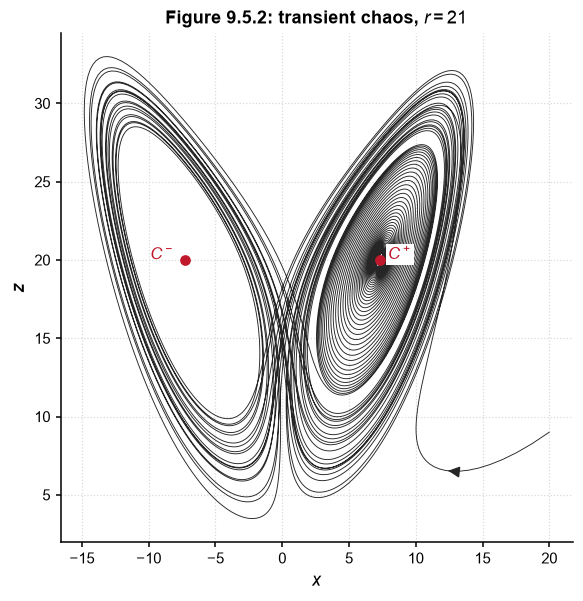

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x21, z21, lw=0.6, color=INK)
k = 8     # arrowhead on the trajectory, pointing along the flow
ax.annotate('', xy=(x21[k + 1], z21[k + 1]), xytext=(x21[k], z21[k]),
            arrowprops=dict(arrowstyle='-|>', color=INK, lw=1, mutation_scale=15))
ax.plot([xC, -xC], [r - 1, r - 1], 'o', color=RED, ms=6, zorder=5)
ax.text(xC + 0.6, r - 1, '$C^+$', color=RED, fontweight='bold',
        bbox=dict(fc='white', ec='none', pad=1)); ax.text(-xC - 2.6, r - 1, '$C^-$', color=RED, fontweight='bold')
ax.set_xlabel('$x$'); ax.set_ylabel('$z$')
ax.set_title(f'Figure 9.5.2: transient chaos, $r={r}$')
plt.show()

**Figure 9.5.2.** The trajectory switches irregularly between the two lobes, then spirals into $C^+$ (red dot).

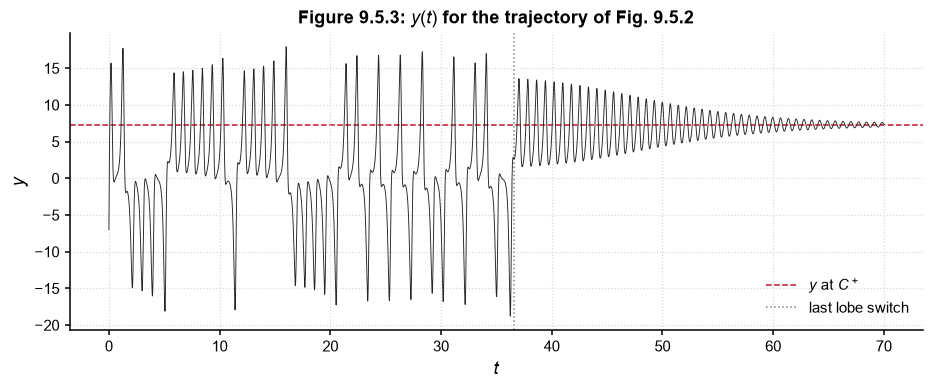

In [8]:
# Output.to_pyleo labels time as 'years CE' (pyleoclim's default; see #53). Lorenz time is
# dimensionless, so we set the axis label ourselves.
ts21 = out21.to_pyleo('y')
fig, ax = ts21.plot(figsize=(10, 3.5), color=INK, linewidth=0.6, legend=False,
                    xlabel='$t$', ylabel='$y$',
                    title='Figure 9.5.3: $y(t)$ for the trajectory of Fig. 9.5.2')
ax.axhline(xC, color=RED, lw=1, ls='--', label='$y$ at $C^+$', zorder=0)
ax.axvline(t_out[switch[-1]], color='0.5', lw=1, ls=':', label='last lobe switch', zorder=0)
ax.legend(loc='lower right')
plt.show()

**Figure 9.5.3.** The same trajectory as a time series. A nearby initial condition, $(20, -7, 7)$, wanders for almost 80 time units and ends at $C^-$ instead:

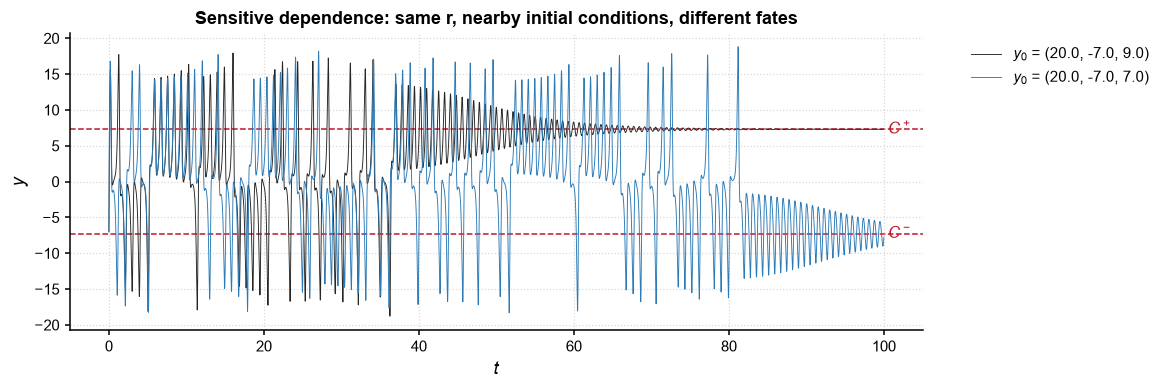

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.5))
t_long = np.linspace(0, 100, 20001)
for y0_, c in [([20.0, -7.0, 9.0], INK), ([20.0, -7.0, 7.0], BLUE)]:
    o = Lorenz63(rho=r).integrate(t_span=(0, 100), y0=y0_, output_time=t_long)
    o.to_pyleo('y').plot(ax=ax, color=c, linewidth=0.6, legend=False,
                         label=f'$y_0$ = {tuple(y0_)}', xlabel='$t$', ylabel='$y$')
for sgn, lab in [(1, '$C^+$'), (-1, '$C^-$')]:
    ax.axhline(sgn * xC, color=RED, lw=1, ls='--', zorder=0)
    ax.text(100.5, sgn * xC, lab, color=RED, fontweight='bold', va='center')
ax.legend(loc='upper left', bbox_to_anchor=(1.04, 1))
ax.set_title('Sensitive dependence: same r, nearby initial conditions, different fates')
plt.show()

<a id="large-r"></a>
## Large r: a globally attracting limit cycle (Figures 9.5.4 and 9.5.5)

This reproduces Example 9.5.2 of the book. At $r=350$ we start near $C^+$, which is now unstable, and the trajectory spirals out onto a limit cycle.

In [10]:
r = 350
xC = np.sqrt(b * (r - 1))
y0 = [30.0, 32.0, 380.0]
t_end = 5
t_out = np.linspace(0, t_end, 10001)

out350 = Lorenz63(rho=r).integrate(t_span=(0, t_end), y0=y0, output_time=t_out)
x350, y350, z350 = (out350.state_variables[v] for v in 'xyz')

print(f"C+ = ({xC:.2f}, {xC:.2f}, {r - 1})")

# Period of the limit cycle: the lag that best maps y(t) onto itself after the transient.
# (y crosses zero several times per period, so zero crossings would be ambiguous.)
late = t_out > 2
dt = t_out[1] - t_out[0]
lags = np.arange(int(0.2 / dt), int(2.0 / dt))
ys = y350[late]
mis = np.array([np.abs(ys[l:] - ys[:-l]).mean() for l in lags])
T350 = lags[np.argmin(mis)] * dt
print(f"Limit-cycle period at r = 350: T = {T350:.3f}")

C+ = (30.51, 30.51, 349)
Limit-cycle period at r = 350: T = 0.389


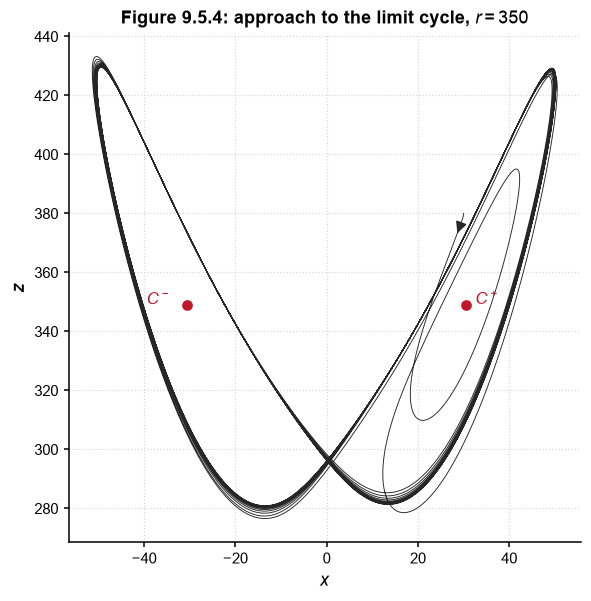

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x350, z350, lw=0.6, color=INK)
k = 40    # arrowhead on the trajectory, pointing along the flow
ax.annotate('', xy=(x350[k + 1], z350[k + 1]), xytext=(x350[k], z350[k]),
            arrowprops=dict(arrowstyle='-|>', color=INK, lw=1, mutation_scale=15))
ax.plot([xC, -xC], [r - 1, r - 1], 'o', color=RED, ms=6, zorder=5)
ax.text(xC + 2, r - 1, '$C^+$', color=RED, fontweight='bold'); ax.text(-xC - 9, r - 1, '$C^-$', color=RED, fontweight='bold')
ax.set_xlabel('$x$'); ax.set_ylabel('$z$')
ax.set_title(f'Figure 9.5.4: approach to the limit cycle, $r={r}$')
plt.show()

**Figure 9.5.4.** The trajectory leaves $C^+$ in growing loops and is captured by a limit cycle that is symmetric about the $z$-axis.

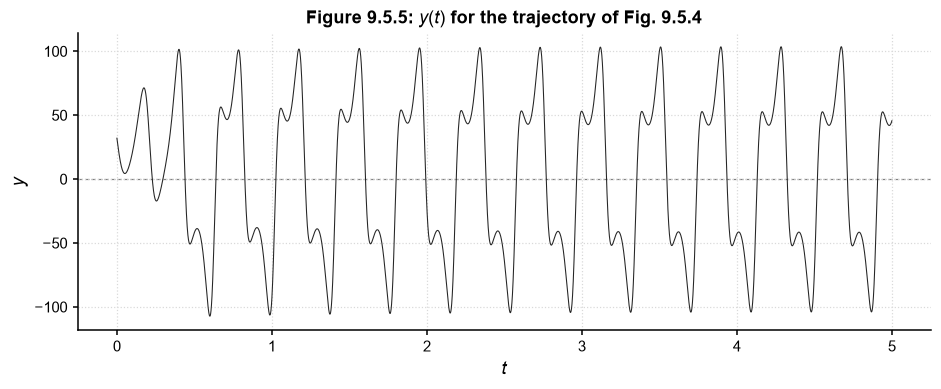

In [12]:
ts350 = out350.to_pyleo('y')      # time label overridden, as for Fig. 9.5.3
fig, ax = ts350.plot(figsize=(10, 3.5), color=INK, linewidth=0.7, legend=False,
                     xlabel='$t$', ylabel='$y$',
                     title='Figure 9.5.5: $y(t)$ for the trajectory of Fig. 9.5.4')
ax.axhline(0, color='0.5', lw=0.8, ls='--', zorder=0)
plt.show()

**Figure 9.5.5.** After a short transient, $y(t)$ settles into a periodic waveform.

<a id="hysteresis"></a>
## Beyond the figures: hysteresis near $r_H$

Strogatz (§9.5) briefly discusses the range $28<r<313$, where chaos alternates with periodic windows. Here we look at a narrower range, $24.06<r<24.74$, where Figure 9.5.1 shows two attractors: the strange attractor and the stable fixed points $C^\pm$. Which one a trajectory ends up on depends on its history, so a slow sweep of $r$ up and then back down should trace a hysteresis loop (Exercise 9.5.4 of the book).

ClimateCritters can run this sweep directly. A `cc.forcing.Ramp` sequence, compiled into a `cc.Forcing`, is passed as `rho`, so $r$ changes during a single integration. We ramp $r$ from 22 to 26 and back over $2\times4000$ time units, starting near $C^+$.

up-sweep:   leaves C+ at r = 25.62   (r_H = 24.74)
down-sweep: settles at   r = 23.05   (strange-attractor onset: 24.06)


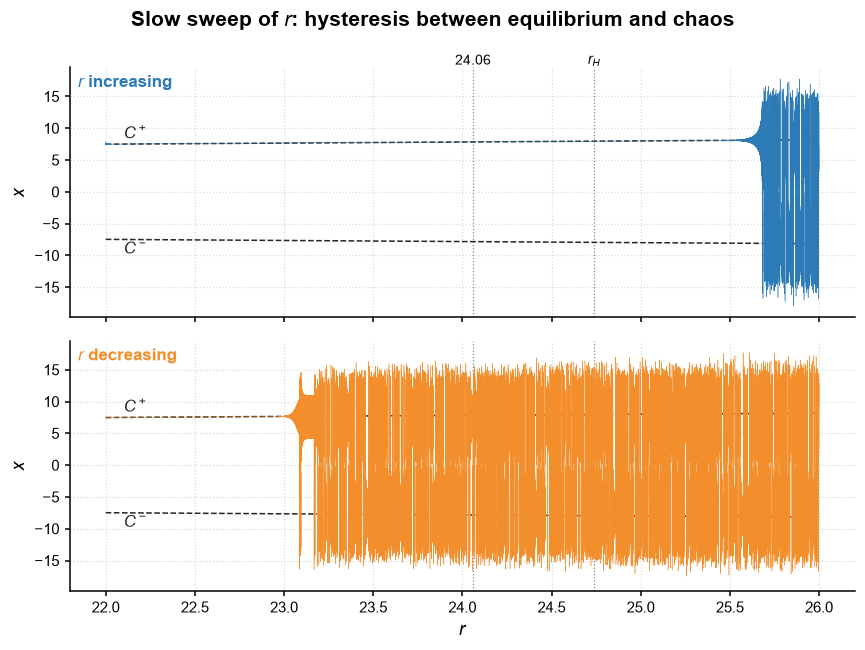

In [13]:
T_ramp, r_lo, r_hi = 4000.0, 22.0, 26.0
rho_sweep = (cc.forcing.Ramp(T_ramp, y0=r_lo, yf=r_hi)
             + cc.forcing.Ramp(T_ramp, y0=r_hi, yf=r_lo)).compile()

xC_lo = np.sqrt(b * (r_lo - 1))
t_sw = np.arange(0, 2 * T_ramp, 0.01)
out_sw = Lorenz63(sigma=sigma, rho=rho_sweep, beta=b).integrate(
    t_span=(0, 2 * T_ramp), y0=[xC_lo + 0.5, xC_lo, r_lo - 1], output_time=t_sw,
    kwargs={'rtol': 1e-9, 'atol': 1e-9})
x_sw, z_sw = out_sw.state_variables['x'], out_sw.state_variables['z']
r_sw = np.array([rho_sweep.get_forcing(t) for t in t_sw])

# Classify each point as "near C+ or C-" (within distance 1 in the x-z plane) or "chaotic"
xC_sw = np.sqrt(b * (r_sw - 1))
dist = np.minimum(np.hypot(x_sw - xC_sw, z_sw - (r_sw - 1)),
                  np.hypot(x_sw + xC_sw, z_sw - (r_sw - 1)))
going_up = t_sw < T_ramp
r_jump_up = r_sw[going_up & (dist > 1)].min()       # first departure from C+ on the way up
r_settle_down = r_sw[~going_up & (dist > 1)].min()  # last chaotic point on the way down
print(f"up-sweep:   leaves C+ at r = {r_jump_up:.2f}   (r_H = {r_H:.2f})")
print(f"down-sweep: settles at   r = {r_settle_down:.2f}   (strange-attractor onset: 24.06)")

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
rr = np.linspace(r_lo, r_hi, 200)
s = slice(None, None, 5)
for ax, mask, color, lab in [(axes[0], going_up, BLUE, '$r$ increasing'),
                             (axes[1], ~going_up, ORANGE, '$r$ decreasing')]:
    ax.plot(r_sw[mask][s], x_sw[mask][s], color=color, lw=0.3, zorder=3)   # in front of C+/-
    for sgn, name in [(1, '$C^+$'), (-1, '$C^-$')]:
        ax.plot(rr, sgn * np.sqrt(b * (rr - 1)), '--', color=INK, lw=1, zorder=2)
        ax.text(r_lo + 0.1, sgn * (np.sqrt(b * (r_lo - 1)) + 1.6), name, color=INK,
                fontweight='bold', ha='left', va='center')
    for rv in (24.06, r_H):
        ax.axvline(rv, color='0.5', lw=0.8, ls=':', zorder=1)
    ax.set_ylabel('$x$')
    ax.text(0.01, 0.97, lab, transform=ax.transAxes, ha='left', va='top', color=color,
            fontweight='bold')
for rv, lab in [(24.06, '24.06'), (r_H, '$r_H$')]:
    axes[0].text(rv, axes[0].get_ylim()[1], lab, ha='center', va='bottom', fontsize=9)
axes[1].set_xlabel('$r$')
fig.suptitle('Slow sweep of $r$: hysteresis between equilibrium and chaos')
fig.tight_layout()
plt.show()

**Hysteresis loop.** The dashed curves are $C^\pm$. On the way up (top) the trajectory tracks $C^+$ well past $r_H$ before it jumps onto the strange attractor. On the way down (bottom) the chaos persists below $r_H$, and the trajectory settles onto a fixed point only well below 24.06. The loop is wider than the book's interval at both ends, for two reasons. First, the ramp is not quasi-static. During the up-sweep the trajectory is drawn very close to $C^+$, and just past $r_H$ the instability is so weak that escaping takes a long time: this is the *delayed loss of stability* of a slow passage through a Hopf bifurcation. Second, just below 24.06 the chaos is transient, but the transients last a very long time (see Yorke & Yorke 1979). Slower ramps narrow the loop toward $[24.06, r_H]$, at a higher computational cost. With `T_ramp = 16000` (about 80 s), for example, the jumps move to $r\approx25.17$ on the way up and $r\approx23.72$ on the way down.

One last caveat: whether the trajectory ends on $C^+$ or $C^-$ depends sensitively on the ramp and the tolerances, as in the sensitivity plot above.

## References

- Kaplan, J. L., and J. A. Yorke, 1979: Preturbulence: A regime observed in a fluid flow model of Lorenz. *Commun. Math. Phys.*, 67, 93–108, [doi:10.1007/BF01221359](https://doi.org/10.1007/BF01221359).
- Lorenz, E. N., 1963: Deterministic nonperiodic flow. *J. Atmos. Sci.*, 20, 130–141, [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2).
- Sparrow, C., 1982: *The Lorenz Equations: Bifurcations, Chaos, and Strange Attractors*. Springer, [doi:10.1007/978-1-4612-5767-7](https://doi.org/10.1007/978-1-4612-5767-7).
- Strogatz, S. H., 2015: *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press, Sections 9.2 and 9.5.
- Yorke, J. A., and E. D. Yorke, 1979: Metastable chaos: The transition to sustained chaotic behavior in the Lorenz model. *J. Stat. Phys.*, 21, 263–277, [doi:10.1007/BF01011469](https://doi.org/10.1007/BF01011469).